# EDA de reference - NutriScope (TP10)

Objectif: produire l'EDA de reference du projet, rejouable de haut en bas.

Credit donnees: © Open Food Facts contributors - ODbL

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

from IPython.display import Image, display

import sys
sys.path.insert(0, '../src')

from eda_lib import (
    clean_minimal_tp10,
    filter_known_rayon,
    resume_univarie,
    profil_par_rayon,
    crosstab_percent_and_cramers_v,
    completude_par_groupe,
    incoherences_metier,
    correlations_nutriscore,
    paires_redondantes,
    correlations_par_rayon,
    extremes_restants,
    comparer_deux_groupes,
)

warnings.filterwarnings('ignore')
np.random.seed(42)

FIG_DIR = Path('figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR = Path('../docs/data')
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def figure(fig, nom):
    path = FIG_DIR / f'{nom}.png'
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
    return path

## 0. Donnees

### Question
Quel est le perimetre de travail et quel niveau de nettoyage est applique ?

### Methode
Cas degrade: chargement de l'echantillon partage puis nettoyage minimal autonome du module (doublons code-barres, bornes nutriments 0-100, energie 0-900). Le rayon unknown est conserve dans les volumeries globales mais exclu des comparaisons par rayon.

In [2]:
DATA_PATH = Path('../docs/annexes/data/echantillon_france.csv')
raw = pd.read_csv(DATA_PATH, low_memory=False)
clean = clean_minimal_tp10(raw)
known = filter_known_rayon(clean, 'pnns_groups_1')

print(f'Volume brut: {len(raw):,}')
print(f'Volume apres nettoyage minimal: {len(clean):,}')
print(f'Volume hors rayon unknown: {len(known):,}')
print(f'Part unknown: {(1 - len(known)/len(clean)):.1%}')

Volume brut: 8,689
Volume apres nettoyage minimal: 8,408
Volume hors rayon unknown: 6,682
Part unknown: 20.5%


## 1. Distributions des nutriments cles par rayon

### Question
Comment se distribuent sucres, sel et energie selon les rayons ?

In [3]:
cles = ['sugars_100g', 'salt_100g', 'energy-kcal_100g']
resume_tbl = pd.DataFrame({c: resume_univarie(clean[c]) for c in cles}).T
resume_tbl[['n_valid','n_missing','median','iqr','mad','mean','std']].round(3)

,n_valid,n_missing,median,iqr,mad,mean,std
sugars_100g,6735.0,1673.0,3.2,16.400,4.744,13.155,19.900
salt_100g,6496.0,1912.0,0.5,1.243,0.726,1.161,3.647
energy-kcal_100g,6799.0,1609.0,253.0,286.900,212.012,272.148,190.581


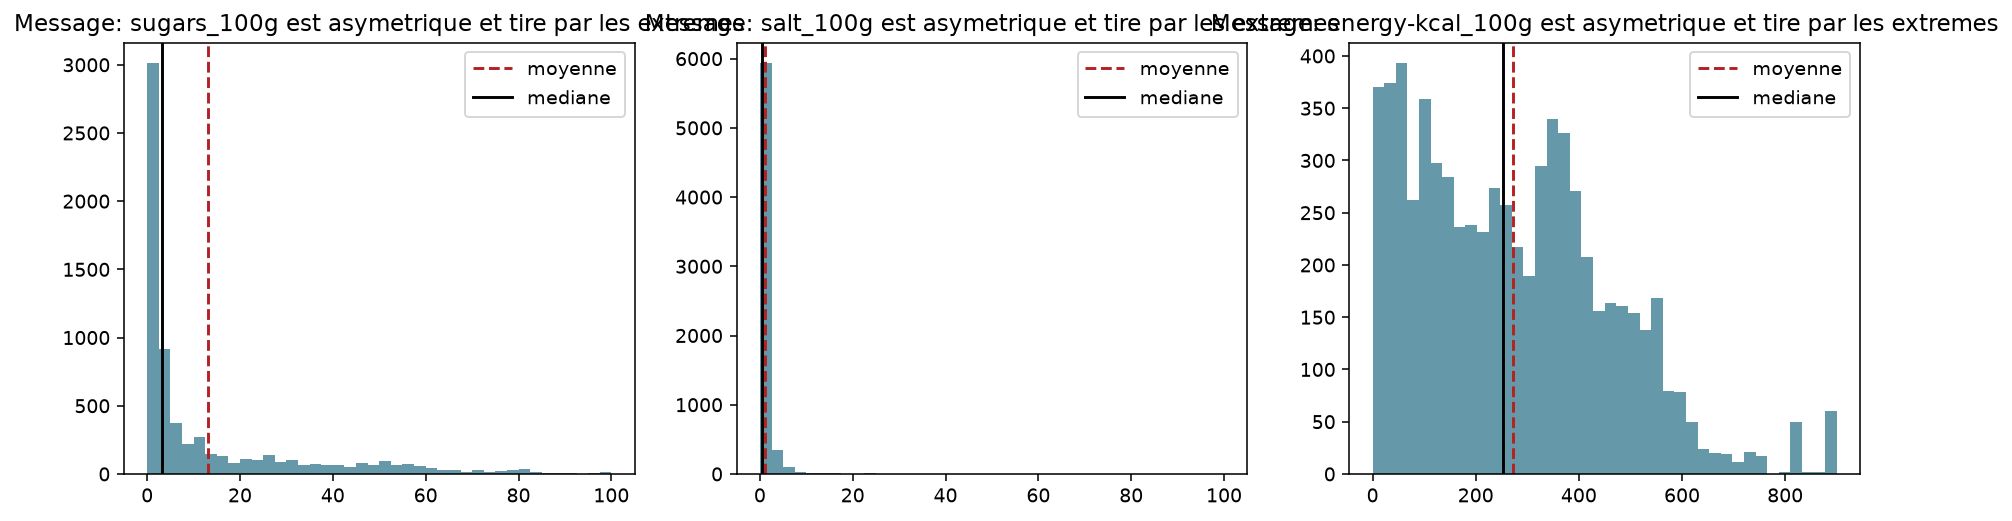

WindowsPath('figures/01_hist_nutriments_cles.png')

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, cles):
    x = pd.to_numeric(clean[col], errors='coerce').dropna()
    ax.hist(x, bins=40, alpha=0.8, color='#3f7f93')
    if len(x):
        ax.axvline(x.mean(), color='firebrick', linestyle='--', label='moyenne')
        ax.axvline(x.median(), color='black', linestyle='-', label='mediane')
    ax.set_title(f'Message: {col} est asymetrique et tire par les extremes')
    ax.legend()
figure(fig, '01_hist_nutriments_cles')

In [5]:
prof, rayons_petits = profil_par_rayon(clean, ['sugars_100g', 'salt_100g'], min_n=30)
prof.head()

,pnns_groups_1,nutriment,n,mean,median,q1,q3
0,Alcoholic beverages,sugars_100g,43,6.355442,0.14,0.000,5.50
1,Baby foods,sugars_100g,50,10.300800,5.60,2.325,10.50
2,Beverages,sugars_100g,452,10.138185,6.10,0.145,10.47
3,Cereals and potatoes,sugars_100g,607,4.940882,2.70,1.000,4.50
4,Composite foods,sugars_100g,458,3.101523,2.20,1.100,3.40


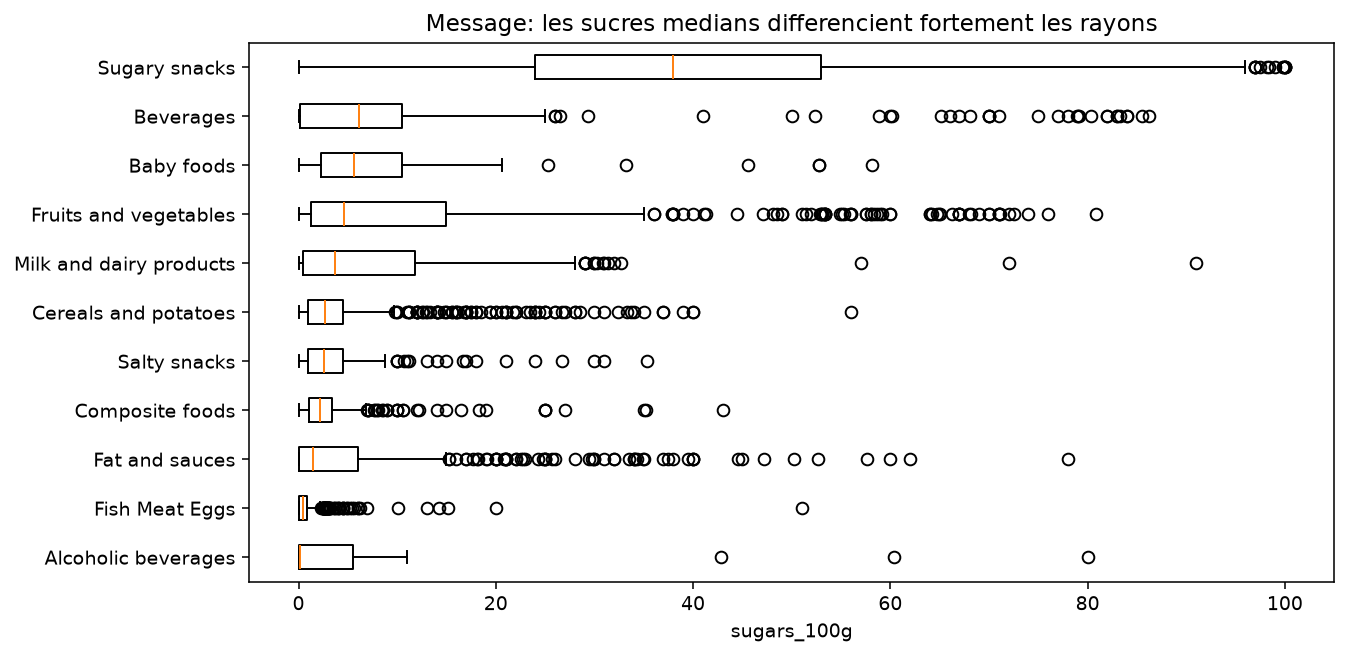

WindowsPath('figures/02_box_sucres_par_rayon.png')

In [6]:
sugar_prof = prof[prof['nutriment'] == 'sugars_100g'].sort_values('median')

fig, ax = plt.subplots(figsize=(10, 5))

ax.boxplot([pd.to_numeric(known.loc[known['pnns_groups_1'] == g, 'sugars_100g'], errors='coerce').dropna() for g in sugar_prof['pnns_groups_1']], tick_labels=sugar_prof['pnns_groups_1'], vert=False)

ax.set_title('Message: les sucres medians differencient fortement les rayons')

ax.set_xlabel('sugars_100g')

figure(fig, '02_box_sucres_par_rayon')

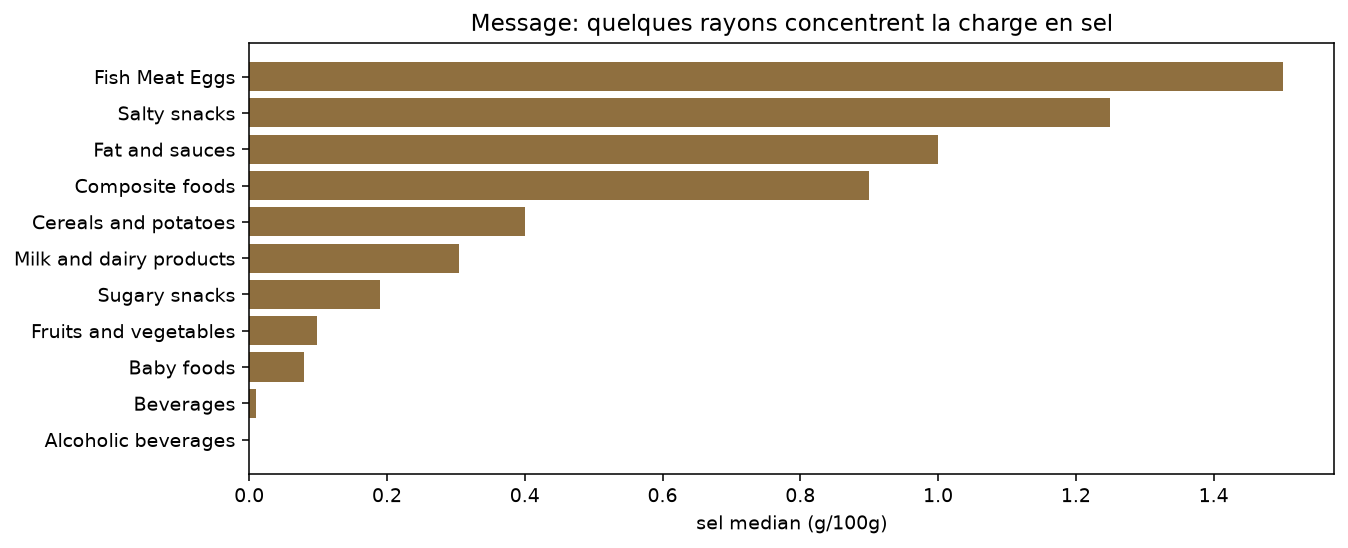

WindowsPath('figures/03_bar_sel_median_par_rayon.png')

In [7]:
salt_prof = prof[prof['nutriment'] == 'salt_100g'].sort_values('median', ascending=False)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(salt_prof['pnns_groups_1'], salt_prof['median'], color='#8f6f3f')
ax.invert_yaxis()
ax.set_title('Message: quelques rayons concentrent la charge en sel')
ax.set_xlabel('sel median (g/100g)')
figure(fig, '03_bar_sel_median_par_rayon')

In [8]:
grades = known[known['nutriscore_grade'].isin(list('abcde'))].copy()
cross_pct, cramers_v = crosstab_percent_and_cramers_v(grades, 'pnns_groups_1', 'nutriscore_grade')
cross_pct.head(), cramers_v

(nutriscore_grade              a          b          c          d          e
 pnns_groups_1                                                              
 Alcoholic beverages    0.000000  50.000000   0.000000   0.000000  50.000000
 Beverages              6.896552  24.403183  27.586207  17.241379  23.872679
 Cereals and potatoes  33.274956  19.789842  26.269702  16.812609   3.852890
 Composite foods        8.387097  15.913978  48.387097  23.655914   3.655914
 Fat and sauces         6.388206  20.638821  20.393120  15.970516  36.609337,
 0.34123374549424323)

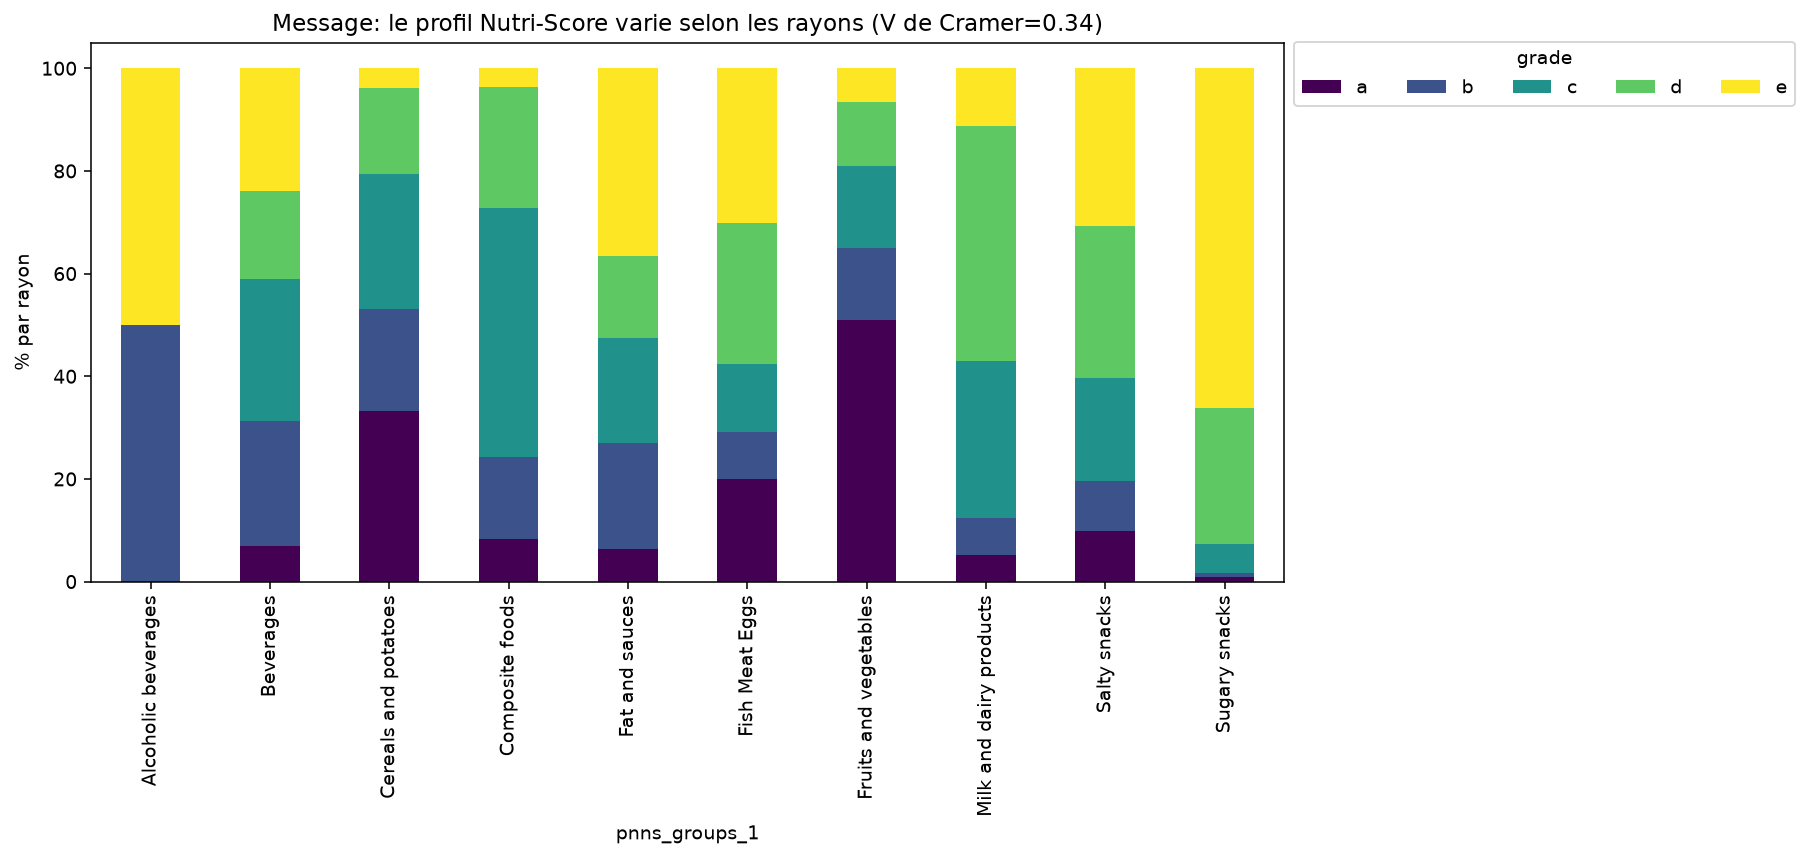

WindowsPath('figures/04_stacked_rayon_grade.png')

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
cross_pct.sort_index().plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
ax.set_title(f'Message: le profil Nutri-Score varie selon les rayons (V de Cramer={cramers_v:.2f})')
ax.set_ylabel('% par rayon')
ax.legend(title='grade', ncol=5, bbox_to_anchor=(1, 1.02))
figure(fig, '04_stacked_rayon_grade')

Interpretation (3 lignes):
1. Les distributions sont tres asymetriques, la mediane est l'indicateur central prioritaire.
2. Les differenciations par rayon sont nettes sur sucres et sel, ce qui justifie une stratification metier.
3. Le rayon doit etre conserve comme feature candidate pour TP14.

Decision: inclure pnns_groups_1 comme variable explicative et conserver les indicateurs robustes (mediane, IQR, MAD).

## 2. Completude et qualite par rayon et par marque

In [10]:
nutri_cols = ['energy-kcal_100g', 'sugars_100g', 'salt_100g', 'fat_100g', 'carbohydrates_100g', 'proteins_100g']
comp_rayon = completude_par_groupe(known, 'pnns_groups_1', nutri_cols, min_n=20)
comp_marque = completude_par_groupe(known, 'brands', nutri_cols, min_n=20)
comp_rayon.head(), comp_marque.head()

(             pnns_groups_1     n  presence_energy-kcal_100g  \
 0            Sugary snacks  1388                   0.855187   
 1           Fish Meat Eggs  1175                   0.811064   
 2  Milk and dairy products   775                   0.868387   
 3     Cereals and potatoes   679                   0.902798   
 4                Beverages   547                   0.855576   
 
    presence_sugars_100g  presence_salt_100g  presence_fat_100g  \
 0              0.853746            0.821326           0.852305   
 1              0.800000            0.800851           0.811064   
 2              0.859355            0.842581           0.865806   
 3              0.893962            0.861561           0.898380   
 4              0.826325            0.808044           0.844607   
 
    presence_carbohydrates_100g  presence_proteins_100g  taux_fiches_completes  \
 0                     0.852305                0.852305               0.814121   
 1                     0.807660               

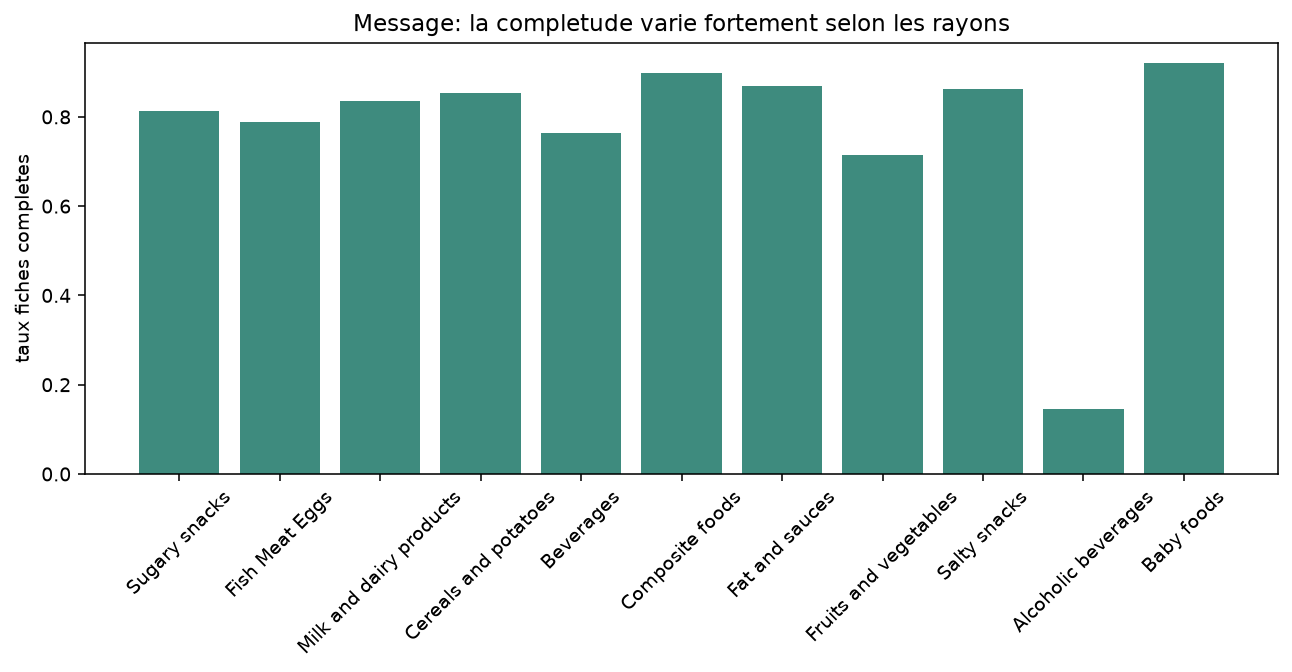

WindowsPath('figures/05_completude_rayon.png')

In [11]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(comp_rayon['pnns_groups_1'], comp_rayon['taux_fiches_completes'], color='#3e8b7e')
ax.set_title('Message: la completude varie fortement selon les rayons')
ax.set_ylabel('taux fiches completes')
ax.tick_params(axis='x', rotation=45)
figure(fig, '05_completude_rayon')

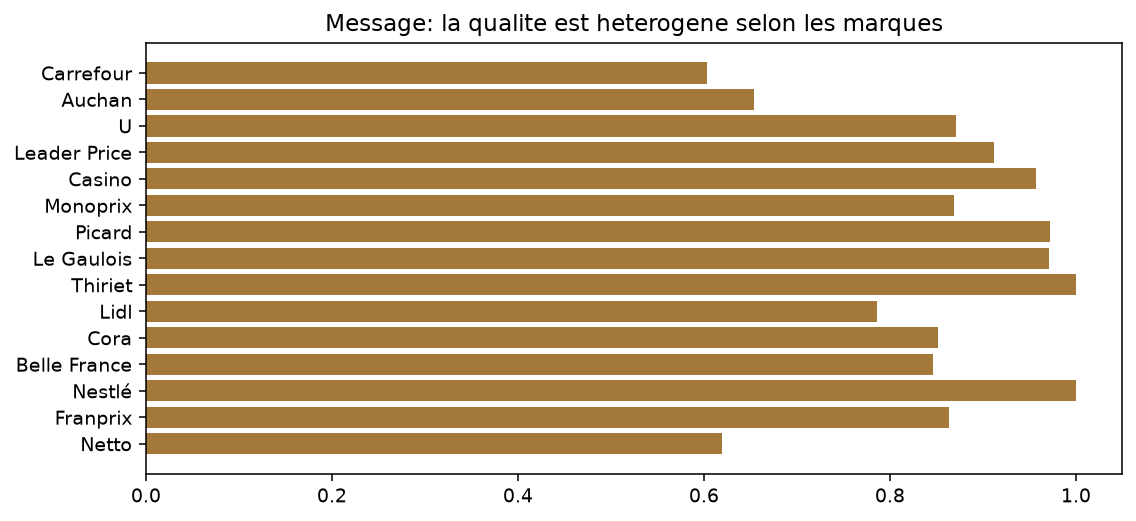

In [12]:
if len(comp_marque):
    fig, ax = plt.subplots(figsize=(9, 4))
    top_b = comp_marque.sort_values('n', ascending=False).head(15)
    ax.barh(top_b['brands'], top_b['taux_fiches_completes'], color='#a37839')
    ax.invert_yaxis()
    ax.set_title('Message: la qualite est heterogene selon les marques')
    figure(fig, '06_completude_marque')
else:
    print('Aucune marque avec n>=20 dans cet echantillon.')

In [13]:
inco = incoherences_metier(clean)
inco_rates = inco.mean().sort_values(ascending=False)
inco_rates

satures_sup_lipides          0.015699
sucres_sup_glucides          0.014867
sel_diff_sodium              0.012488
energie_ecart_150            0.007850
energie_nulle_avec_macros    0.002735
dtype: float64

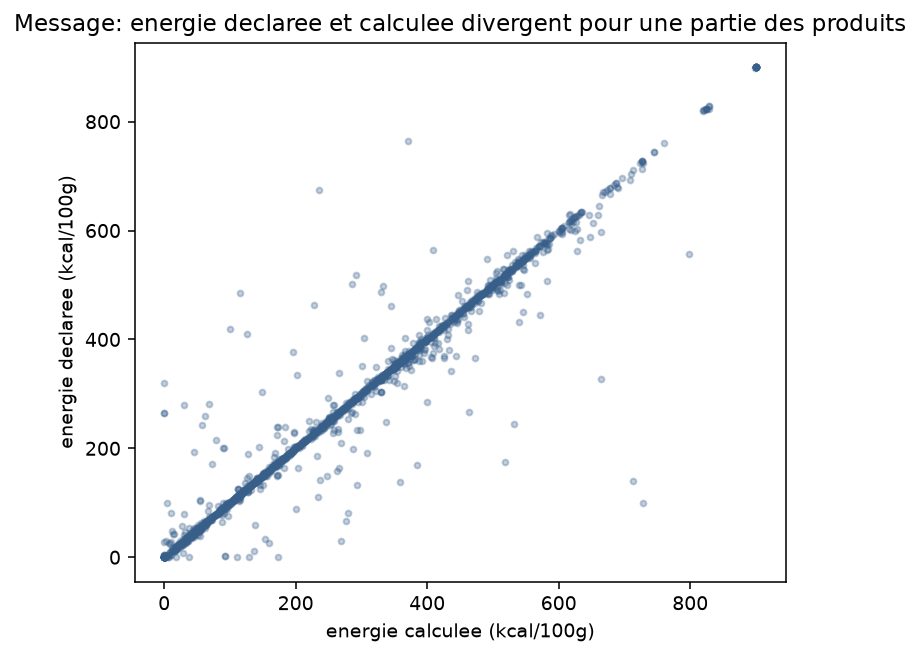

WindowsPath('figures/07_scatter_energie.png')

In [14]:
tmp = clean.copy()
tmp['energy_calc'] = (9*pd.to_numeric(tmp['fat_100g'], errors='coerce') + 4*pd.to_numeric(tmp['carbohydrates_100g'], errors='coerce') + 4*pd.to_numeric(tmp['proteins_100g'], errors='coerce') + 2*pd.to_numeric(tmp['fiber_100g'], errors='coerce'))
plot_df = tmp[['energy-kcal_100g', 'energy_calc']].dropna().sample(min(2000, tmp[['energy-kcal_100g', 'energy_calc']].dropna().shape[0]), random_state=42)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(plot_df['energy_calc'], plot_df['energy-kcal_100g'], s=9, alpha=0.3, color='#375f8a')
ax.set_title('Message: energie declaree et calculee divergent pour une partie des produits')
ax.set_xlabel('energie calculee (kcal/100g)')
ax.set_ylabel('energie declaree (kcal/100g)')
figure(fig, '07_scatter_energie')

Interpretation (3 lignes):
1. La completude n'est pas uniforme: certains rayons et certaines marques sont plus fiables.
2. Les drapeaux d'incoherence metier indiquent des zones de prudence avant modelisation.
3. Les regles de controle doivent rester actives dans TP9/TP14.

Decision: appliquer des seuils de confiance par segment et conserver les drapeaux qualite en variables de suivi.

## 3. Correlations nutriments ↔ Nutri-Score

In [15]:
corr_vars = ['energy-kcal_100g','fat_100g','saturated-fat_100g','carbohydrates_100g','sugars_100g','fiber_100g','proteins_100g','salt_100g','sodium_100g']
corr_tbl = correlations_nutriscore(known, corr_vars, 'nutriscore_score', min_n=30)
corr_tbl

,variable,n,pearson,spearman
0,saturated-fat_100g,5011,0.472537,0.538193
1,energy-kcal_100g,5016,0.442371,0.525597
2,fat_100g,5016,0.301841,0.465079
3,sugars_100g,5013,0.476263,0.391570
4,salt_100g,5017,0.309572,0.386781
5,sodium_100g,5017,0.300724,0.381518
6,carbohydrates_100g,5013,0.304730,0.268369
7,fiber_100g,2702,-0.084426,-0.079482
8,proteins_100g,5016,0.029906,0.055844


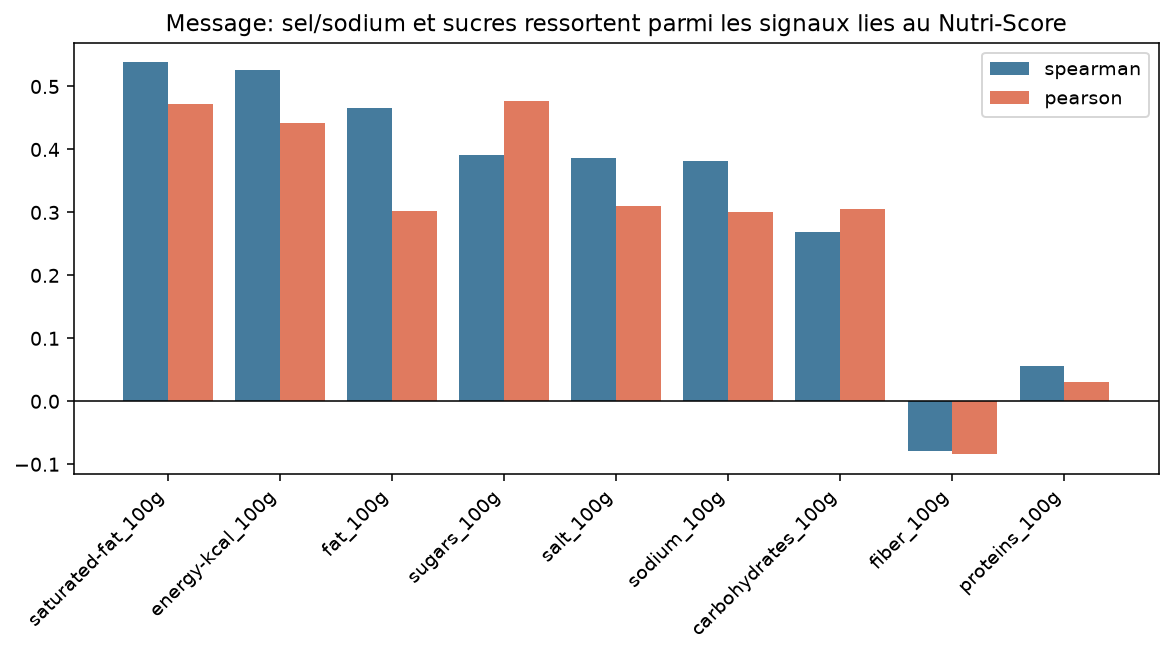

WindowsPath('figures/08_corr_nutriscore.png')

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(corr_tbl))
ax.bar(x - 0.2, corr_tbl['spearman'], width=0.4, label='spearman', color='#457b9d')
ax.bar(x + 0.2, corr_tbl['pearson'], width=0.4, label='pearson', color='#e07a5f')
ax.set_xticks(x)
ax.set_xticklabels(corr_tbl['variable'], rotation=45, ha='right')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Message: sel/sodium et sucres ressortent parmi les signaux lies au Nutri-Score')
ax.legend()
figure(fig, '08_corr_nutriscore')

In [17]:
mat = known[corr_vars].apply(pd.to_numeric, errors='coerce').corr(method='spearman')
redondances = paires_redondantes(mat, seuil=0.8)
redondances.head()

,var_a,var_b,corr,abs_corr
0,salt_100g,sodium_100g,0.989957,0.989957
1,fat_100g,saturated-fat_100g,0.891883,0.891883


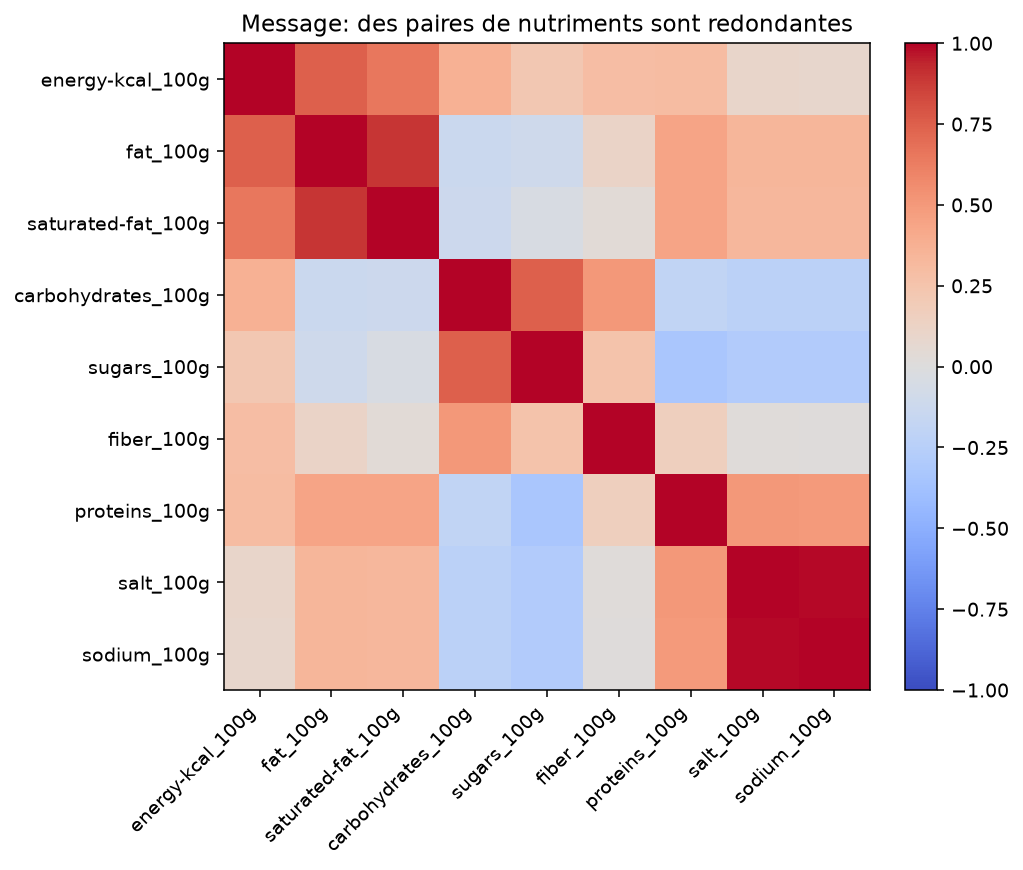

WindowsPath('figures/09_heatmap_spearman.png')

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(mat.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(mat.columns)))
ax.set_yticks(range(len(mat.index)))
ax.set_xticklabels(mat.columns, rotation=45, ha='right')
ax.set_yticklabels(mat.index)
ax.set_title('Message: des paires de nutriments sont redondantes')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
figure(fig, '09_heatmap_spearman')

In [19]:
corr_sugars_rayon = correlations_par_rayon(known, 'sugars_100g', min_n=30)
corr_salt_rayon = correlations_par_rayon(known, 'salt_100g', min_n=30)
corr_sugars_rayon.head(), corr_salt_rayon.head()

(             pnns_groups_1     n  spearman   pearson
 0            Sugary snacks  1078  0.301049  0.329965
 1           Fish Meat Eggs   908  0.332984  0.127119
 2  Milk and dairy products   614 -0.296794  0.027884
 3     Cereals and potatoes   553  0.311982  0.417160
 4          Composite foods   444  0.211760  0.291365,
              pnns_groups_1     n  spearman   pearson
 0            Sugary snacks  1078  0.280714  0.197413
 1           Fish Meat Eggs   909  0.829306  0.593434
 2  Milk and dairy products   616  0.694962  0.549091
 3     Cereals and potatoes   553  0.683301  0.499654
 4          Composite foods   444  0.640386  0.414987)

Interpretation (3 lignes):
1. Les correlations globales donnent un signal initial mais doivent etre relues par rayon.
2. Les paires redondantes (ex: sel/sodium) suggerent une reduction de variables pour TP14.
3. Le sens et l'intensite des liens varient selon les segments metier.

Decision: conserver Spearman comme reference, retirer une variable dans les paires redondantes fortes, et entrainer des modeles stratifies ou avec interaction rayon.

## 4. Valeurs extremes restantes

In [20]:
ext = extremes_restants(known, ['energy-kcal_100g','sugars_100g','salt_100g'], seuil=3.5)
ext.head(15)

,pnns_groups_1,code,product_name,value,variable,z_robuste
0,Beverages,3256221106381,Eau minérale naturelle gazeuse fines bulles 6x1l,77.500000,salt_100g,5226.621074
1,Beverages,87703157828,with Aloe Vera,30.000000,salt_100g,2022.794761
2,Beverages,6130093056999,ifruit orange mangue au lait,7.840000,salt_100g,528.125474
3,Alcoholic beverages,4013200225902,Nick Maple-sirup,80.000000,sugars_100g,384.748225
4,Alcoholic beverages,3180290028377,Giffard crème de cassis d'Anjou 16°,60.364000,sugars_100g,290.146219
5,Alcoholic beverages,4901309015855,Sauce Mirin pour cuisine japonaise,42.800000,sugars_100g,205.526662
6,Beverages,8888196172419,Pokka Ice Peach Tea,3.000000,salt_100g,201.672435
7,Fruits and vegetables,3017800109731,Haricots Verts extra-fins en fagotins (4 fagot...,16.307667,salt_100g,111.563817
8,Beverages,5000243800042,Capsules NESCAFE DOLCE GUSTO Avoine 12 capsules,1.460000,salt_100g,97.801014
9,Fish Meat Eggs,2492868037393,Saucisson à cuire,51.000000,sugars_100g,80.145253


Interpretation (3 lignes):
1. Une partie des extremes est plausible (huiles, confiseries, condiments tres sales).
2. Une partie reste residuelle et doit etre transformee en drapeaux de controle.
3. La relecture metier produit des regles actionnables pour le pipeline de nettoyage.

Decision: ajouter deux drapeaux proposes pour TP9: sel_>15g_100g hors condiments, energie_0_avec_macros_positifs.

## 5. Hypotheses et registre

\n
Nous utilisons un choix adaptatif: Welch quand les deux groupes ont une forme assez proche de la symetrie et des variances comparables, Mann-Whitney sinon. L'objectif est de garder un test coherent avec la forme des donnees, pas de maximiser artificiellement la significativite.

In [21]:
from scipy import stats



def _numeric_pair(a, b):

    x = pd.to_numeric(a, errors='coerce').dropna()

    y = pd.to_numeric(b, errors='coerce').dropna()

    return x, y



def choisir_test(a, b):

    x, y = _numeric_pair(a, b)

    if len(x) < 20 or len(y) < 20:

        return 'mannwhitney'

    skew_ok = max(abs(x.skew()), abs(y.skew())) < 1.0

    var_x = x.var(ddof=1)

    var_y = y.var(ddof=1)

    var_ratio = np.inf if min(var_x, var_y) == 0 else max(var_x, var_y) / min(var_x, var_y)

    if skew_ok and var_ratio < 4:

        return 'welch'

    return 'mannwhitney'



def comparer_groupes_adaptatif(a, b):

    x, y = _numeric_pair(a, b)

    if len(x) < 2 or len(y) < 2:

        return {'test': 'insufficient_data', 'n_a': len(x), 'n_b': len(y), 'statistique': np.nan, 'p_value': np.nan, 'effet': np.nan, 'median_a': np.nan, 'median_b': np.nan}



    test = choisir_test(x, y)

    if test == 'welch':

        res = stats.ttest_ind(x, y, equal_var=False)

        pooled = np.sqrt((x.var(ddof=1) + y.var(ddof=1)) / 2)

        effet = (x.mean() - y.mean()) / pooled if pooled else np.nan

        return {

            'test': 'welch',

            'n_a': len(x),

            'n_b': len(y),

            'statistique': float(res.statistic),

            'p_value': float(res.pvalue),

            'effet': float(effet),

            'median_a': float(x.median()),

            'median_b': float(y.median()),

            'mean_a': float(x.mean()),

            'mean_b': float(y.mean()),

        }



    res = stats.mannwhitneyu(x, y, alternative='two-sided')

    effet = 1 - (2 * res.statistic) / (len(x) * len(y))

    return {

        'test': 'mannwhitney',

        'n_a': len(x),

        'n_b': len(y),

        'statistique': float(res.statistic),

        'p_value': float(res.pvalue),

        'effet': float(effet),

        'median_a': float(x.median()),

        'median_b': float(y.median()),

        'mean_a': float(x.mean()),

        'mean_b': float(y.mean()),

    }



h_rows = []



comparaisons = [

    ('H1 sucres(DE) > sucres(AB)', known.loc[known['nutriscore_grade'].isin(['d','e']), 'sugars_100g'], known.loc[known['nutriscore_grade'].isin(['a','b']), 'sugars_100g']),

    ('H2 energie snacks sucres > fruits/legumes', known.loc[known['pnns_groups_1'] == 'Sugary snacks', 'energy-kcal_100g'], known.loc[known['pnns_groups_1'] == 'Fruits and vegetables', 'energy-kcal_100g']),

    ('H3 sel(DE) > sel(AB)', known.loc[known['nutriscore_grade'].isin(['d','e']), 'salt_100g'], known.loc[known['nutriscore_grade'].isin(['a','b']), 'salt_100g']),

    ('H4 energie boissons > cereales', known.loc[known['pnns_groups_1'] == 'Beverages', 'energy-kcal_100g'], known.loc[known['pnns_groups_1'] == 'Cereals and potatoes', 'energy-kcal_100g']),

]



for hypothese, groupe_a, groupe_b in comparaisons:

    res = comparer_groupes_adaptatif(groupe_a, groupe_b)

    if res['test'] == 'welch':

        resultat = f"t={res['statistique']:.2f}, p={res['p_value']:.3g}"

    elif res['test'] == 'mannwhitney':

        resultat = f"U={res['statistique']:.0f}, p={res['p_value']:.3g}"

    else:

        resultat = 'NA'



    h_rows.append({

        'hypothese': hypothese,

        'test': res['test'],

        'n_a': res['n_a'],

        'n_b': res['n_b'],

        'resultat': resultat,

        'effet': res['effet'],

        'decision': 'acceptee' if pd.notna(res['p_value']) and res['p_value'] < 0.05 else 'a reformuler',

    })



registre = pd.DataFrame(h_rows)

registre.to_csv(EXPORT_DIR / 'registre_hypotheses.csv', index=False)

registre

,hypothese,test,n_a,n_b,resultat,effet,decision
0,H1 sucres(DE) > sucres(AB),mannwhitney,2732,1248,"U=2493529, p=5.66e-122",-0.462679,acceptee
1,H2 energie snacks sucres > fruits/legumes,mannwhitney,1187,380,"U=413806, p=8.14e-133",-0.834816,acceptee
2,H3 sel(DE) > sel(AB),mannwhitney,2734,1250,"U=2573298, p=1.66e-145",-0.505953,acceptee
3,H4 energie boissons > cereales,mannwhitney,468,613,"U=22214, p=1.36e-125",0.845139,acceptee


Mise en garde: ces tests restent exploratoires (EDA). La rigueur inferentielle complete est reservee au module 3.4.

## 6. Synthese et export
Le notebook exporte ses figures dans notebooks/figures et le registre dans docs/data/registre_hypotheses.csv.
La synthese textuelle finale est redigee dans docs/data/synthese_eda.md.